## 1.Data Investigation and Validation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r"C:\Users\Laveena\Downloads\Afficionado Coffee Roasters.xlsx - Transactions.csv")

df.head()

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,7:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,7:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,7:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,7:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,7:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [3]:
df.shape

(149116, 11)

In [4]:
df.columns

Index(['transaction_id', 'year', 'transaction_time', 'transaction_qty',
       'store_id', 'store_location', 'product_id', 'unit_price',
       'product_category', 'product_type', 'product_detail'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   year              149116 non-null  int64  
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  object 
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  object 
 9   product_type      149116 non-null  object 
 10  product_detail    149116 non-null  object 
dtypes: float64(1), int64(5), object(5)
memory usage: 12.5+ MB


In [6]:
df.isnull().sum()

transaction_id      0
year                0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

In [7]:
df["transaction_id"].duplicated().sum()

np.int64(0)

In [8]:
(df["transaction_qty"] <= 0).sum()

np.int64(0)

In [9]:
(df["unit_price"] <= 0).sum()

np.int64(0)

In [10]:
df["transaction_time"] = pd.to_datetime(
    df["transaction_time"],
    format="%H:%M:%S"
)

In [11]:
df["transaction_time"].head()

0   1900-01-01 07:06:11
1   1900-01-01 07:08:56
2   1900-01-01 07:14:04
3   1900-01-01 07:20:24
4   1900-01-01 07:22:41
Name: transaction_time, dtype: datetime64[ns]

## 2.Feature Engineering -- Temporal

In [12]:
df["Revenue"] = (
    df["transaction_qty"] *
    df["unit_price"]
)

In [13]:
df["hour"] = df["transaction_time"].dt.hour

In [14]:
df["hour"].unique()

array([ 7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,  6, 20],
      dtype=int32)

In [15]:
def time_bucket(hour):
    if 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 16:
        return "Afternoon"
    elif 17 <= hour <= 21:
        return "Evening"
    else:
        return "Late hours"

In [16]:
df["time_bucket"] = df["hour"].apply(time_bucket)

In [17]:
df[["hour", "time_bucket"]].head(20)

,hour,time_bucket
0,7,Morning
1,7,Morning
2,7,Morning
3,7,Morning
4,7,Morning
5,7,Morning
6,7,Morning
7,7,Morning
8,7,Morning
9,7,Morning


## 3.Sales Trend Analysis

In [18]:
total_transactions = df["transaction_id"].count()
total_quantity = df["transaction_qty"].sum()
total_revenue = df["Revenue"].sum()

print("Total Transactions:", total_transactions)
print("Total Quantity Sold:", total_quantity)
print("Total Revenue:", total_revenue)

Total Transactions: 149116
Total Quantity Sold: 214470
Total Revenue: 698812.3300000001


In [19]:
store_summary = df.groupby("store_location").agg(
    transactions=("transaction_id", "count"),
    quantity=("transaction_qty", "sum"),
    revenue=("Revenue", "sum")
).reset_index()


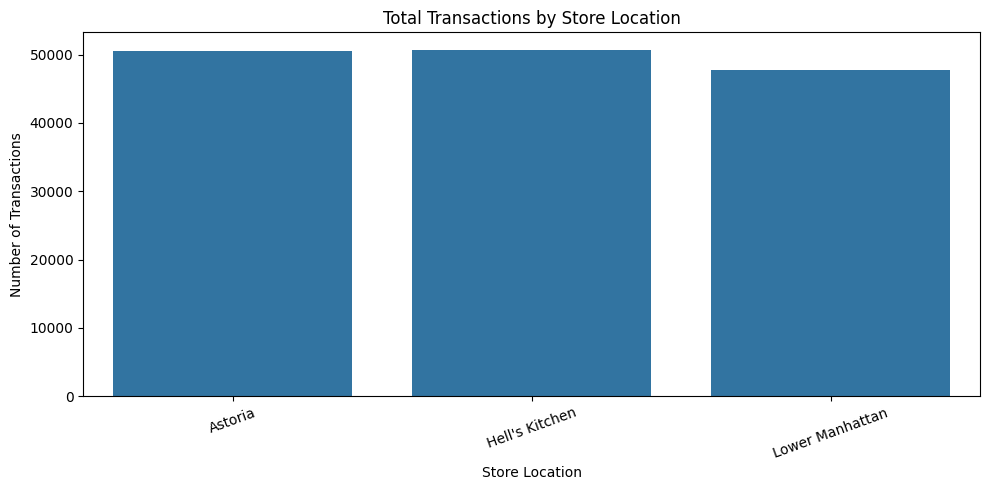

In [20]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=store_summary,
    x="store_location",
    y="transactions"
)

plt.title("Total Transactions by Store Location")
plt.xlabel("Store Location")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

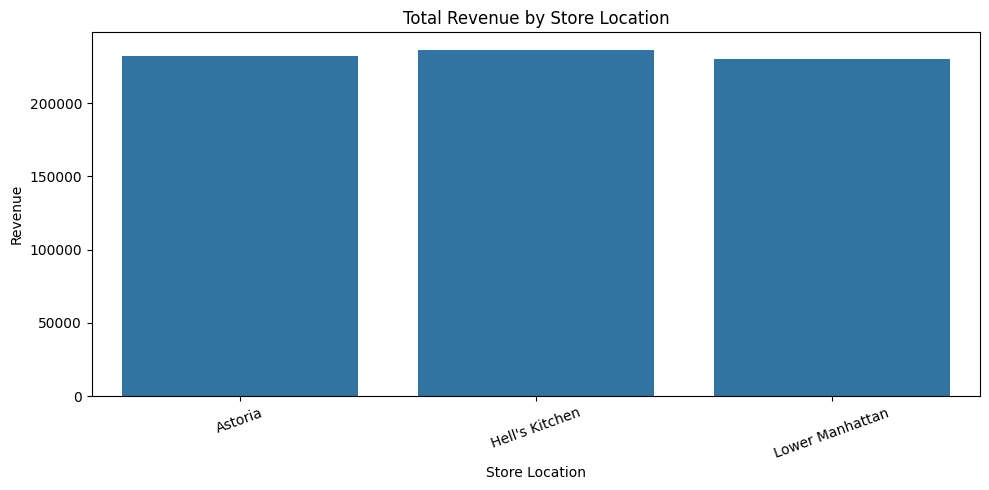

In [21]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=store_summary,
    x="store_location",
    y="revenue"
)

plt.title("Total Revenue by Store Location")
plt.xlabel("Store Location")
plt.ylabel("Revenue")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## 4.Day-of-week Performance Analysis

In [22]:
print("""
Day-of-week analysis cannot be performed reliably because
the available dataset does not contain the actual transaction date.
The transaction_time column contains only time-of-day information.
Therefore, Monday-Sunday and weekday-weekend comparisons are excluded.
""")


Day-of-week analysis cannot be performed reliably because
the available dataset does not contain the actual transaction date.
The transaction_time column contains only time-of-day information.
Therefore, Monday-Sunday and weekday-weekend comparisons are excluded.



## 5.Time-of-Day Demand Analysis

In [23]:
hourly_analysis = df.groupby("hour").agg(
    transactions=("transaction_id", "count"),
    revenue=("Revenue", "sum"),
    quantity=("transaction_qty", "sum")
).reset_index()

In [24]:
hourly_analysis

,hour,transactions,revenue,quantity
0,6,4594,21900.27,6865
1,7,13428,63526.47,19449
2,8,17654,82699.87,25197
3,9,17764,85169.53,25370
4,10,18545,88673.39,26713
5,11,9766,46319.14,14035
6,12,8708,40192.79,12690
7,13,8714,40367.45,12439
8,14,8933,41304.74,12907
9,15,8979,41733.10,12923


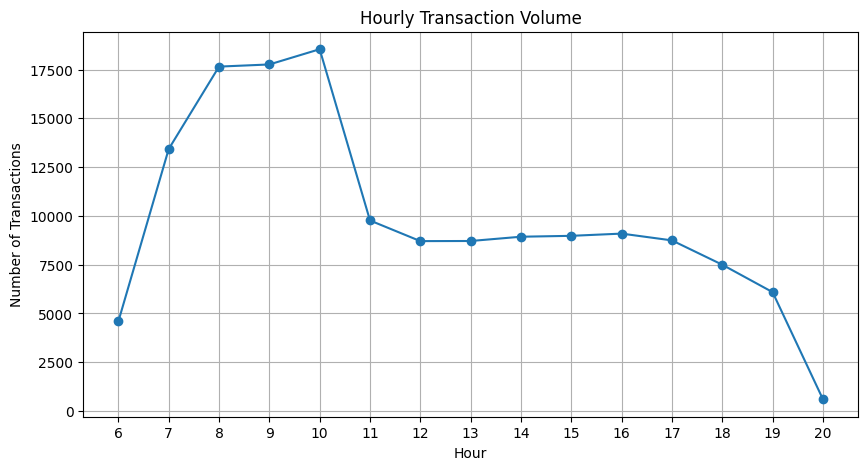

In [25]:
plt.figure(figsize=(10,5))

plt.plot(
    hourly_analysis["hour"],
    hourly_analysis["transactions"],
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Number of Transactions")
plt.title("Hourly Transaction Volume")

plt.xticks(range(6,21))
plt.grid()

plt.show()

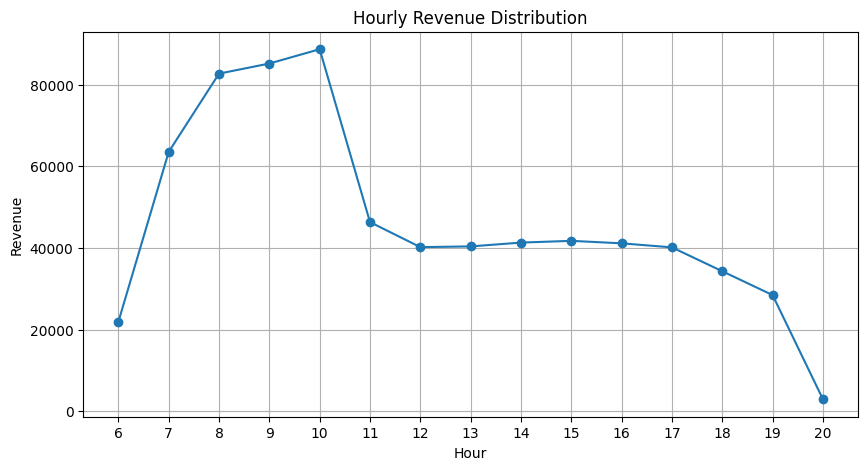

In [26]:
plt.figure(figsize=(10,5))

plt.plot(
    hourly_analysis["hour"],
    hourly_analysis["revenue"],
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Revenue")
plt.title("Hourly Revenue Distribution")

plt.xticks(range(6,21))
plt.grid()

plt.show()

In [27]:
peak_transaction_hour = hourly_analysis.loc[
    hourly_analysis["transactions"].idxmax()
]

print(
    "Peak Transaction Hour:",
    peak_transaction_hour["hour"]
)

print(
    "Transactions:",
    peak_transaction_hour["transactions"]
)

Peak Transaction Hour: 10.0
Transactions: 18545.0


In [28]:
peak_revenue_hour = hourly_analysis.loc[
    hourly_analysis["revenue"].idxmax()
]

print(
    "Peak Revenue Hour:",
    peak_revenue_hour["hour"]
)

print(
    "Revenue:",
    peak_revenue_hour["revenue"]
)

Peak Revenue Hour: 10.0
Revenue: 88673.39


## 6.Time-Bucket Analysis

In [29]:
time_analysis = df.groupby("time_bucket").agg(
    transactions=("transaction_id", "count"),
    revenue=("Revenue", "sum"),
    quantity=("transaction_qty", "sum")
).reset_index()

In [30]:
time_analysis

,time_bucket,transactions,revenue,quantity
0,Afternoon,44427,204720.83,63840
1,Evening,22938,105802.83,33001
2,Morning,81751,388288.67,117629


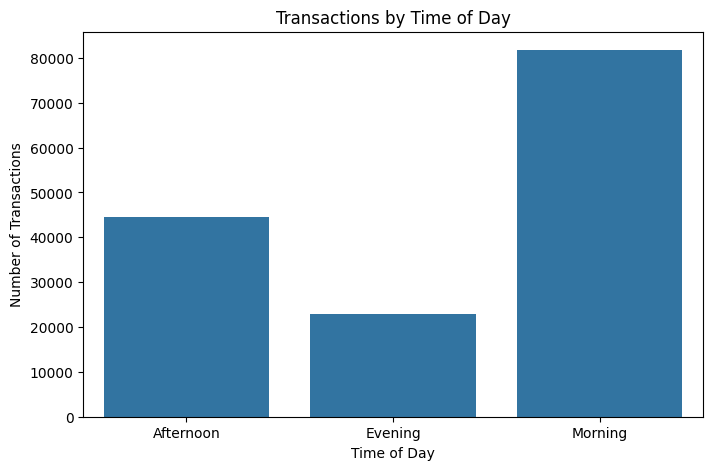

In [31]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=time_analysis,
    x="time_bucket",
    y="transactions"
)

plt.title("Transactions by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Number of Transactions")

plt.show()

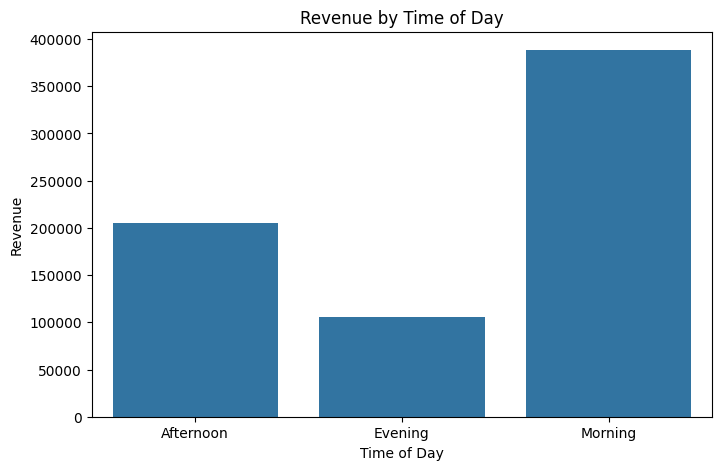

In [32]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=time_analysis,
    x="time_bucket",
    y="revenue"
)

plt.title("Revenue by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Revenue")

plt.show()

## 7.Cross-Location Temporal Comparison

In [33]:
store_hour = df.groupby(
    ["store_location", "hour"]
).agg(
    transactions=("transaction_id", "count"),
    quantity=("transaction_qty", "sum"),
    revenue=("Revenue", "sum")
).reset_index()

In [34]:
store_hour.head()

,store_location,hour,transactions,quantity,revenue
0,Astoria,7,4181,5865,19028.80
1,Astoria,8,4966,6756,22805.90
2,Astoria,9,5083,7055,23183.57
3,Astoria,10,5291,7388,24426.12
4,Astoria,11,3413,4892,15498.13


## 8.Hourly Heatmap per Store

In [35]:
heatmap_data = store_hour.pivot(
    index="store_location",
    columns="hour",
    values="transactions"
)

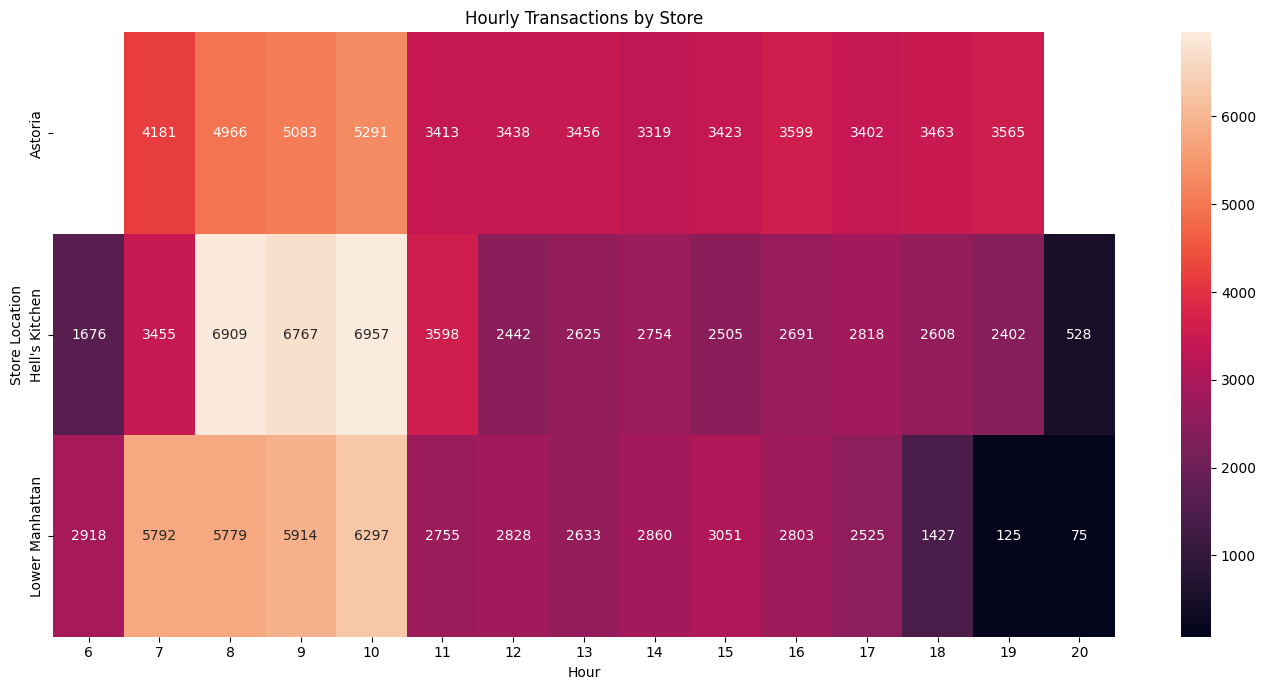

In [36]:
plt.figure(figsize=(14,7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f"
)

plt.title("Hourly Transactions by Store")
plt.xlabel("Hour")
plt.ylabel("Store Location")

plt.tight_layout()
plt.show()

## 9.Peak Hour for Each Store

In [37]:
store_peak_hour = store_hour.loc[
    store_hour.groupby("store_location")["transactions"].idxmax()
]

In [38]:
store_peak_hour[
    ["store_location", "hour", "transactions"]
]

,store_location,hour,transactions
3,Astoria,10,5291
17,Hell's Kitchen,10,6957
32,Lower Manhattan,10,6297


## 10.Location-Specific Customer Behavior

In [39]:
store_behavior = store_hour.groupby(
    "store_location"
).agg(
    total_transactions=("transactions", "sum"),
    total_quantity=("quantity", "sum"),
    total_revenue=("revenue", "sum")
).reset_index()

In [40]:
store_behavior

,store_location,total_transactions,total_quantity,total_revenue
0,Astoria,50599,70991,232243.91
1,Hell's Kitchen,50735,71737,236511.17
2,Lower Manhattan,47782,71742,230057.25


## Streamlit Dashboard

In [41]:
%%writefile app.py

import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Afficionado Coffee Roasters",
    page_icon="☕",
    layout="wide"
)

st.title("☕ Afficionado Coffee Roasters")

st.subheader(
    "Sales Trend and Time-Based Performance Analysis"
)

st.write(
    "Interactive dashboard for analyzing transaction volume, "
    "revenue, time-of-day demand, and store-level performance."
)

Overwriting app.py


In [42]:
%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# 1. PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Afficionado Coffee Roasters",
    page_icon="☕",
    layout="wide"
)


# ============================================================
# 2. TITLE
# ============================================================

st.title("☕ Afficionado Coffee Roasters")

st.subheader(
    "Sales Trend and Time-Based Performance Analysis"
)

st.write(
    "Interactive dashboard for analyzing transaction volume, "
    "revenue, time-of-day demand, and store-level performance."
)


# ============================================================
# 3. UPLOAD DATASET
# ============================================================

uploaded_file = st.file_uploader(
    "Upload Coffee Sales CSV Dataset",
    type=["csv"]
)


# ============================================================
# 4. RUN DASHBOARD AFTER FILE UPLOAD
# ============================================================

if uploaded_file is not None:

    df = pd.read_csv(uploaded_file)


    # ========================================================
    # 5. DATA PREPARATION
    # ========================================================

    df["transaction_time"] = pd.to_datetime(
        df["transaction_time"],
        format="%H:%M:%S"
    )

    # Revenue
    df["Revenue"] = (
        df["transaction_qty"] *
        df["unit_price"]
    )

    # Hour
    df["hour"] = df["transaction_time"].dt.hour


    # Time buckets
    def time_bucket(hour):

        if 6 <= hour <= 11:
            return "Morning"

        elif 12 <= hour <= 16:
            return "Afternoon"

        elif 17 <= hour <= 21:
            return "Evening"

        else:
            return "Late hours"


    df["time_bucket"] = df["hour"].apply(time_bucket)


    # ========================================================
    # 6. SIDEBAR FILTERS
    # ========================================================

    st.sidebar.header("Dashboard Filters")


    # Store Location
    store_options = [
        "All Stores"
    ] + sorted(
        df["store_location"].dropna().unique().tolist()
    )


    selected_store = st.sidebar.selectbox(
        "Select Store Location",
        store_options
    )


    # Copy dataframe
    filtered_df = df.copy()


    # Apply store filter
    if selected_store != "All Stores":

        filtered_df = filtered_df[
            filtered_df["store_location"] == selected_store
        ]


    # ========================================================
    # 7. HOUR RANGE FILTER
    # ========================================================

    min_hour = int(filtered_df["hour"].min())
    max_hour = int(filtered_df["hour"].max())


    hour_range = st.sidebar.slider(
        "Select Hour Range",
        min_value=min_hour,
        max_value=max_hour,
        value=(min_hour, max_hour)
    )


    # Apply hour filter
    filtered_df = filtered_df[
        (filtered_df["hour"] >= hour_range[0]) &
        (filtered_df["hour"] <= hour_range[1])
    ]


    # ========================================================
    # 8. REVENUE / QUANTITY TOGGLE
    # ========================================================

    metric = st.sidebar.radio(
        "Select Metric",
        ["Revenue", "Quantity"]
    )


    if metric == "Revenue":

        y_value = "revenue"
        y_label = "Revenue"

    else:

        y_value = "quantity"
        y_label = "Quantity Sold"


    # ========================================================
    # 9. DATASET LIMITATION
    # ========================================================

    st.info(
        "Note: The available dataset contains transaction time "
        "but does not contain the actual transaction date. "
        "Therefore, day-of-week and weekday-versus-weekend "
        "analysis cannot be performed reliably."
    )


    # ========================================================
    # 10. OVERALL SALES SUMMARY
    # ========================================================

    st.header("📊 Overall Sales Summary")


    total_transactions = (
        filtered_df["transaction_id"].count()
    )

    total_quantity = (
        filtered_df["transaction_qty"].sum()
    )

    total_revenue = (
        filtered_df["Revenue"].sum()
    )


    col1, col2, col3 = st.columns(3)


    col1.metric(
        "Total Transactions",
        f"{total_transactions:,}"
    )


    col2.metric(
        "Total Quantity Sold",
        f"{total_quantity:,}"
    )


    col3.metric(
        "Total Revenue",
        f"{total_revenue:,.2f}"
    )


    # ========================================================
    # 11. HOURLY DEMAND ANALYSIS
    # ========================================================

    st.header("⏰ Hourly Demand Analysis")


    hourly_dashboard = filtered_df.groupby(
        "hour"
    ).agg(
        transactions=("transaction_id", "count"),
        revenue=("Revenue", "sum"),
        quantity=("transaction_qty", "sum")
    ).reset_index()


    if not hourly_dashboard.empty:

        fig, ax = plt.subplots(
            figsize=(10, 5)
        )


        ax.plot(
            hourly_dashboard["hour"],
            hourly_dashboard[y_value],
            marker="o"
        )


        ax.set_xlabel("Hour")

        ax.set_ylabel(y_label)

        ax.set_title(
            f"Hourly {y_label}"
        )

        ax.grid()


        st.pyplot(
            fig,
            width="stretch"
        )


    # ========================================================
    # 12. TIME-OF-DAY PERFORMANCE
    # ========================================================

    st.header("🕐 Time-of-Day Performance")


    time_dashboard = filtered_df.groupby(
        "time_bucket"
    ).agg(
        transactions=("transaction_id", "count"),
        revenue=("Revenue", "sum"),
        quantity=("transaction_qty", "sum")
    ).reset_index()


    fig, ax = plt.subplots(
        figsize=(8, 5)
    )


    ax.bar(
        time_dashboard["time_bucket"],
        time_dashboard[y_value]
    )


    ax.set_xlabel("Time of Day")

    ax.set_ylabel(y_label)

    ax.set_title(
        f"{y_label} by Time of Day"
    )


    st.pyplot(
        fig,
        width="stretch"
    )


    # ========================================================
    # 13. HOURLY DEMAND HEATMAP
    # ========================================================

    st.header("🔥 Hourly Demand Heatmap")


    store_hour_dashboard = filtered_df.groupby(
        ["store_location", "hour"]
    ).agg(
        transactions=("transaction_id", "count")
    ).reset_index()


    heatmap_data = store_hour_dashboard.pivot(
        index="store_location",
        columns="hour",
        values="transactions"
    )


    fig, ax = plt.subplots(
        figsize=(12, 6)
    )


    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".0f",
        ax=ax
    )


    ax.set_xlabel("Hour")

    ax.set_ylabel("Store Location")

    ax.set_title(
        "Hourly Transactions by Store"
    )


    st.pyplot(
        fig,
        width="stretch"
    )


    # ========================================================
    # 14. STORE LOCATION COMPARISON
    # ========================================================

    st.header("🏪 Store Location Comparison")


    location_comparison = filtered_df.groupby(
        "store_location"
    ).agg(
        transactions=("transaction_id", "count"),
        quantity=("transaction_qty", "sum"),
        revenue=("Revenue", "sum")
    ).reset_index()


    st.dataframe(
        location_comparison,
        width="stretch"
    )


    # ========================================================
    # 15. STORE COMPARISON CHART
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(10, 5)
    )


    ax.bar(
        location_comparison["store_location"],
        location_comparison[y_value]
    )


    ax.set_xlabel("Store Location")

    ax.set_ylabel(y_label)

    ax.set_title(
        f"{y_label} by Store Location"
    )


    plt.xticks(
        rotation=20
    )


    st.pyplot(
        fig,
        width="stretch"
    )


    # ========================================================
    # 16. PEAK HOUR
    # ========================================================

    st.header("⭐ Peak Hour")


    if not hourly_dashboard.empty:

        peak_row = hourly_dashboard.loc[
            hourly_dashboard[y_value].idxmax()
        ]


        st.success(
            f"Peak {y_label.lower()} occurs at "
            f"{int(peak_row['hour'])}:00"
        )


        st.write(
            f"{y_label}: "
            f"{peak_row[y_value]:,.2f}"
        )


    # ========================================================
    # 17. DATASET PREVIEW
    # ========================================================

    st.header("📋 Dataset Preview")


    st.dataframe(
        filtered_df.head(20),
        width="stretch"
    )


else:

    st.warning(
        "Please upload the Coffee Sales CSV dataset "
        "to start the dashboard."
    )

Overwriting app.py


In [43]:
df.to_csv("coffee_sales_cleaned.csv", index=False)

In [44]:
df = pd.read_csv("coffee_sales_cleaned.csv")

In [45]:
import os

print(os.getcwd())

C:\Users\Laveena
